## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Heidi Williams

**Date:** 10/14/2026

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
#Q1
#1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


In [14]:
%cd /content/drive/MyDrive/ML/A04-clustering/data
!ls

/content/drive/MyDrive/ML/A04-clustering/data
'SIPRI Military Expenditure Database.csv'


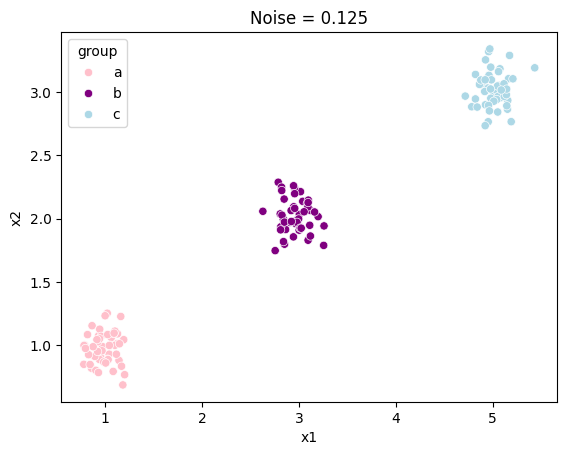

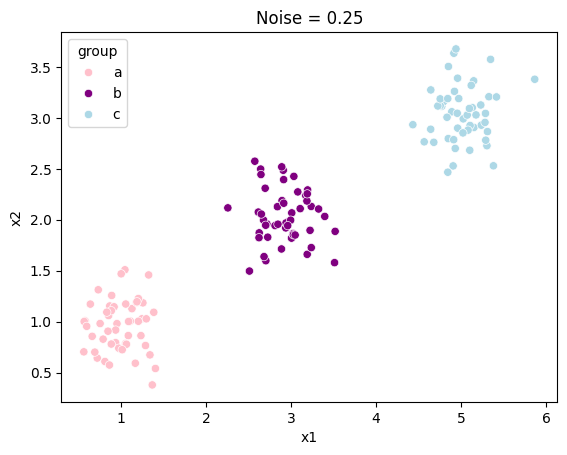

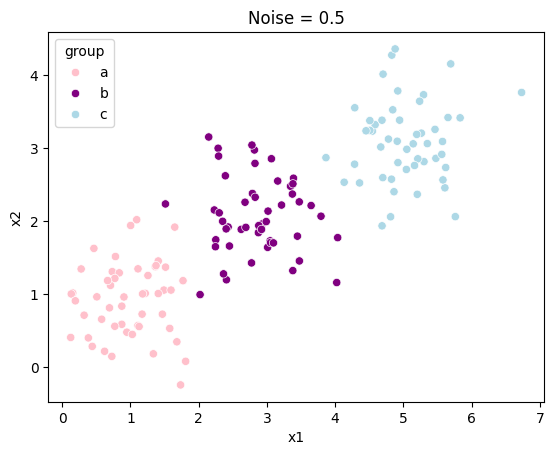

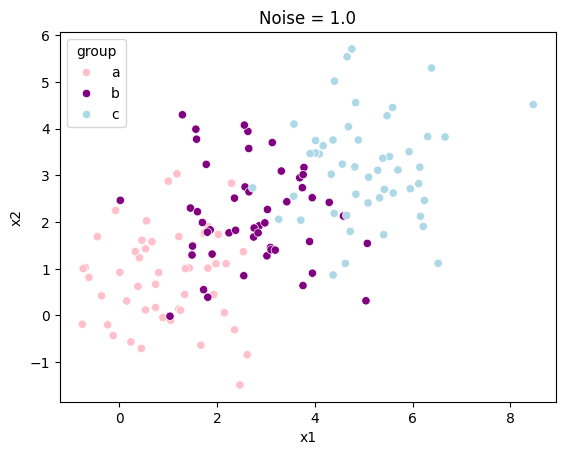

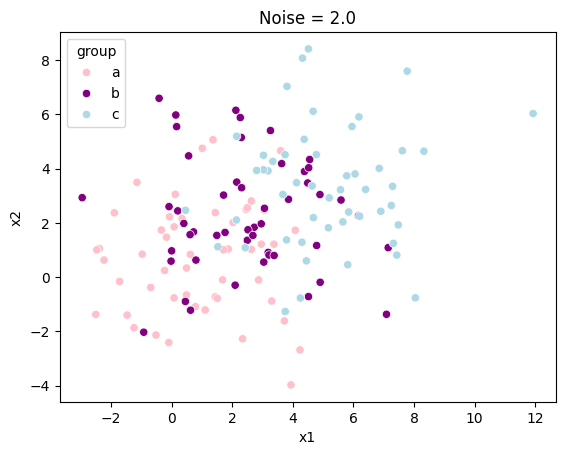

In [16]:
#Q1
#2
import seaborn as sns
import matplotlib.pyplot as plt

for noise in [0.125, 0.25, 0.5, 1.0, 2.0]:
    sns.scatterplot(data=createData(noise), x="x1", y="x2",
                    hue="group", palette=["pink", "purple", "lightblue"])
    plt.title(f"Noise = {noise}")
    plt.show()

Q1 2:
As the noise goes up from 0.125 to 2.0, the clusters go from relatively distinct groups of a b c that are precise, to more spread apart and overlapping with other groups (between a b c).

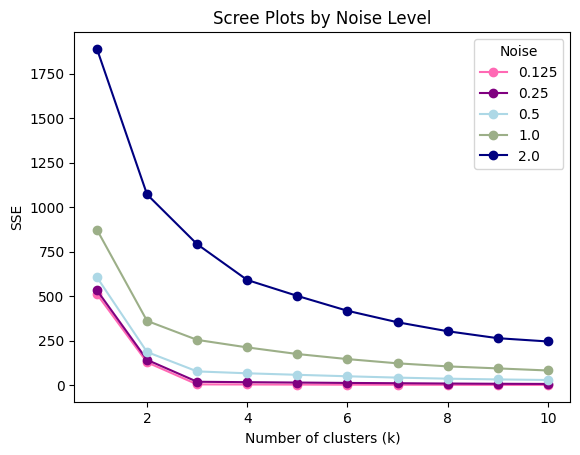

In [18]:
#Q1
#3
from sklearn.cluster import KMeans

colors = ["hotpink", "purple", "lightblue", "#9CAF88", "navy"]

for noise, color in zip([0.125, 0.25, 0.5, 1.0, 2.0], colors):
    X = createData(noise)[["x1", "x2"]]
    sse = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
        sse.append(model.inertia_)

    plt.plot(range(1, 11), sse, marker="o", color=color, label=noise)

plt.xlabel("Number of clusters (k)")
plt.ylabel("SSE")
plt.title("Scree Plots by Noise Level")
plt.legend(title="Noise")
plt.show()

Q1 3: The curves with more noise have higher SSE and keep dropping as more clusters are added, so choosing a clear number of clusters is harder. With less noise, the curves flatten out sooner and show a clearer elbow around k=3. The pink and purple curves, representing noise levels of 0.125 and 0.25, overlap almost completely and have the lowest SSE.

Q1 4: The elbow is where adding more clusters stops making a big difference in SSE. In this simulation, the low-noise data has three clear groups, so increasing k up to 3 greatly reduces SSE. After that, extra clusters mostly split up groups that are already close together, giving smaller improvements. This creates the elbow around k=3. With more noise, the groups overlap and extra clusters keep reducing SSE, so the stopping point is less obvious.

In [22]:
#Q2
#1

df = pd.read_csv("SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna()

print(len(df))

148


I ended up with 148 countries after keeping only 2020 and dropping the missing values. In terms of further cleaning, below is the code for where I kept the country names as labels and removed the index and year since they do not help compare spending. The spending columns were already numeric, but I scaled them so variables with larger values would not have too much influence on the clusters.

In [23]:
df = df.set_index("Country")
df = df.drop(columns=["index", "Year"])
X = (df - df.min()) / (df.max() - df.min())

X.head()

,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
Country,,,,
Afghanistan,0.000348,0.137524,0.150377,0.002620
Albania,0.000230,0.127303,0.110877,0.025615
Algeria,0.012461,0.676168,0.566960,0.087630
Angola,0.001265,0.146191,0.233882,0.011767
Argentina,0.003626,0.073306,0.041498,0.024627


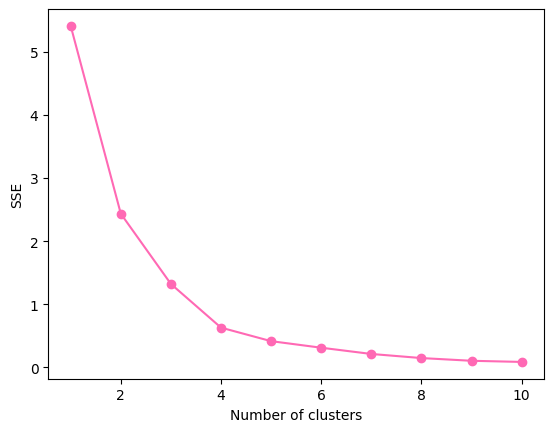

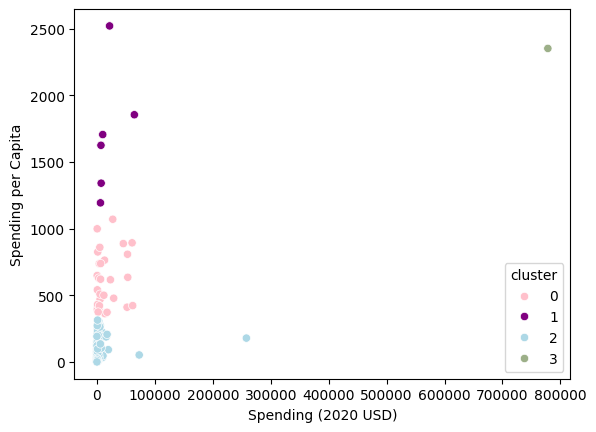

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858

,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
Country,,,,,
United States of America,778397.2,0.037179,0.081976,2351.631858,3


In [24]:
#Q2
#2
columns = ["Spending (2020 USD)", "Spending per Capita"]
X = df[columns]
X = (X - X.min()) / (X.max() - X.min())

sse = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker="o", color="hotpink")
plt.xlabel("Number of clusters")
plt.ylabel("SSE")
plt.show()

model = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

sns.scatterplot(data=df, x=columns[0], y=columns[1],
                hue="cluster", palette=["pink", "purple", "lightblue", "#9CAF88"])
plt.show()

display(df.groupby("cluster")[columns].describe())
display(df.loc[["United States of America"]])


Q2 2: The United States stands out because it is the only country in cluster 3. It spends much more overall than the other countries and also spends a lot per person. China has high total spending too, but it falls into cluster 2 with most countries because its spending per person is much lower.
The other groups seem to separate mostly by spending per person. Cluster 0 includes countries like Canada, Germany, and Japan with moderate amounts, while cluster 1 includes higher per-person spenders like Israel, Kuwait, and Saudi Arabia. I would use four clusters because the scree plot has an "elbow" like described in question 1 around k=4, where adding more clusters starts making less of a difference in SSE.

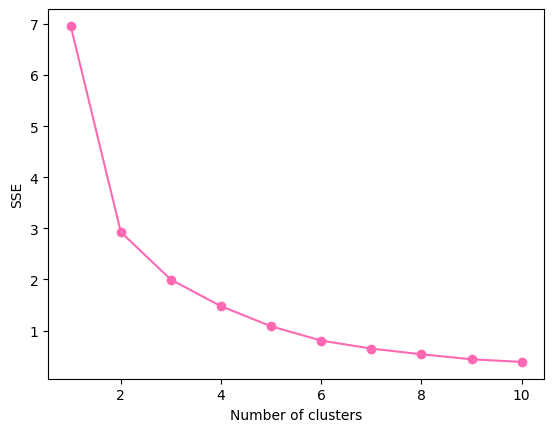

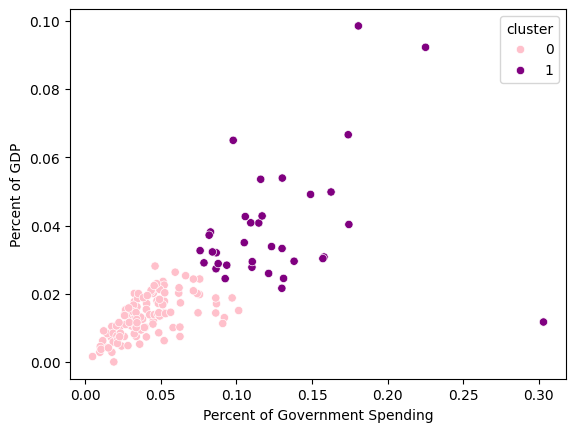

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                113.0  0.041394  0.020681  0.004896   
1                                 35.0  0.126456  0.046209  0.076005   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.026783  0.038486  0.051496  0.101501          113.0  0.013481   
1        0.093093  0.116052  0.143584  0.303027           35.0  0.039433   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.005966  0.000054  0.009147  0.013631  0.017830  0.028132  
1        0.018179  0.011742  0.028962  0.033281  0.042722  0.098470

,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
Country,,,,,
United States of America,778397.2,0.037179,0.081976,2351.631858,1


In [25]:
#Q2
#3
columns = ["Percent of Government Spending", "Percent of GDP"]
X = df[columns]
X = (X - X.min()) / (X.max() - X.min())

sse = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker="o", color="hotpink")
plt.xlabel("Number of clusters")
plt.ylabel("SSE")
plt.show()

model = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

sns.scatterplot(data=df, x=columns[0], y=columns[1],
                hue="cluster", palette=["pink", "purple"])
plt.show()

display(df.groupby("cluster")[columns].describe())
display(df.loc[["United States of America"]])

Q2 3:
Compared to part 2, I would choose two clusters instead of four based on the elbow in the scree plot. The biggest difference is that the United States is no longer in its own cluster. It is now grouped with countries like India, Israel, and Saudi Arabia because its spending relative to GDP and government spending is less unusual than its total spending.

The groups now separate into countries with lower and higher shares going toward the military, with 113 countries in cluster 0 and 35 in cluster 1. This shows how changing the variables changes which countries appear similar.

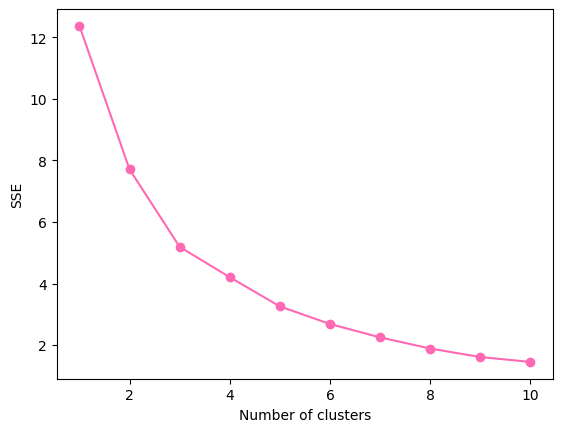

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                     111.0   196.926833  ...                       0.050505   
1                      31.0   212.689100  ...                       0.134663   
2                       6.0  1875.150751  ...                       0.164503   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1        0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
2        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                       
              50%       75%       max  
cluster                                
0        0.013589  0.017769  0.028132  
1        0.032024  0.040531  0.066600  
2        0.059257  0.085398  0.098470  

[3 rows x 32 columns]

,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
Country,,,,,
United States of America,778397.2,0.037179,0.081976,2351.631858,2


In [26]:
#Q2
#4
columns = ["Spending (2020 USD)", "Spending per Capita",
           "Percent of Government Spending", "Percent of GDP"]
X = df[columns]
X = (X - X.min()) / (X.max() - X.min())

sse = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker="o", color="hotpink")
plt.xlabel("Number of clusters")
plt.ylabel("SSE")
plt.show()

model = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

display(df.groupby("cluster")[columns].describe())
display(df.loc[["United States of America"]])

Q2 4: The biggest change is where the United States ends up. With just the spending variables, it was in its own cluster. With just the percentages, it was in a larger group that included India. Using all four puts it in a smaller group with Israel, Kuwait, Oman, Saudi Arabia, and Singapore.
I would choose three clusters here based on the elbow around k=3, compared to four in the first analysis and two in the second. The other two clusters have similar average spending per person, but different shares of GDP and government spending going toward the military. These results reflect both how much countries spend and how large that spending is relative to their economies and budgets.

Q2 5: I think k-means was useful because it showed that there are different ways to compare military spending. China spends a lot overall, but its spending per person puts it with countries that spend much less. The United States also went from being in its own cluster to sharing one when we included spending relative to GDP and government budgets. This helped me see why total spending alone does not give me the full information.

In [34]:
%cd /content/drive/MyDrive/ML/A04-clustering

/content/drive/MyDrive/ML/A04-clustering


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]